# M304 - Scripts optimizados para IA

> Módulo III - Python para la inteligencia artificial
>
> Tema 3: Implementación de scripts optimizados para IA

Contenido:

1. Reporte continuo (curva cuantil/percentil)
2. Reporte discreto (soportes y proporciones)
3. Reporte discretizado (razonamiento)
4. Reporte cruzado (inferencia a la respuesta)

Objetivo: Ensamblar un cubo de datos discretizado

> Generalmente, no se utilizan modelos continuos para realizar inferencias, a menos de ser necesario. Se suele hacer un análisis cruzado.

In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot
import seaborn

## 1. Reporte continuo (curva cuantil/percentil)

Discretización de las variables continuas

In [2]:
titanic = pd.read_csv("../conjuntos/titanic.csv")

c1 = titanic["Survived"].map({
    0: "no",
    1: "yes"
})
c2 = titanic["Sex"]
c3 = titanic["Pclass"].map({
    1: "1st",
    2: "2nd",
    3: "3rd"
})
c4 = titanic["Fare"]
c5 = (~(titanic["Cabin"].isna())).map({
    True: "yes",
    False: "no"
})
c6 = titanic["Embarked"].map({
    "S": "southampton",
    "C": "cherbug",
    "Q": "queenstown",
})
c7 = titanic["Age"]
c8 = titanic["SibSp"]
c9 = titanic["Parch"]

In [3]:
# Bin-cuantil, Cuartiles, Quintiles, Deciles, Dos-deciles, Percentiles

c4_q2 = pd.qcut(c4, q=2) # Q2 (partición por la mediana - 50%)
c4_q2.name = "Fare P2"
c4_q4 = pd.qcut(c4, q=4) # Q1, Q2, Q3 (partición por cuartiles - c/25%)
c4_q4.name = "Fare P4"
c4_q5 = pd.qcut(c4, q=5) # K1, K2, K3, K4 (partición por quintiles - c/20%)
c4_q5.name = "Fare P5"
c4_q10 = pd.qcut(c4, q=10) # D1, D2, .., D9 (partición por deciles - c/10%)
c4_q10.name = "Fare P10"
c4_q20 = pd.qcut(c4, q=20) # V1, V2, ..., V19 (partición por dos-deciles - c/5%)
c4_q20.name = "Fare P20"

In [4]:
# Funciones de partición
def median(serie):
    return serie.quantile(0.5)

def q1(serie):
    return serie.quantile(0.25)
def q2(serie):
    return serie.quantile(0.50)
def q3(serie):
    return serie.quantile(0.75)

def k1(serie):
    return serie.quantile(0.20)
def k2(serie):
    return serie.quantile(0.40)
def k3(serie):
    return serie.quantile(0.60)
def k4(serie):
    return serie.quantile(0.80)

def d1(serie):
    return serie.quantile(0.1)
def d2(serie):
    return serie.quantile(0.2)
def d3(serie):
    return serie.quantile(0.3)
def d4(serie):
    return serie.quantile(0.4)
def d5(serie):
    return serie.quantile(0.5)
def d6(serie):
    return serie.quantile(0.6)
def d7(serie):
    return serie.quantile(0.7)
def d8(serie):
    return serie.quantile(0.8)
def d9(serie):
    return serie.quantile(0.9)

def v1(serie):
    return serie.quantile(0.05)
def v2(serie):
    return serie.quantile(0.1)
def v3(serie):
    return serie.quantile(0.15)
def v4(serie):
    return serie.quantile(0.2)
def v5(serie):
    return serie.quantile(0.25)
def v6(serie):
    return serie.quantile(0.3)
def v7(serie):
    return serie.quantile(0.35)
def v8(serie):
    return serie.quantile(0.4)
def v9(serie):
    return serie.quantile(0.45)
def v10(serie):
    return serie.quantile(0.5)
def v11(serie):
    return serie.quantile(0.55)
def v12(serie):
    return serie.quantile(0.6)
def v13(serie):
    return serie.quantile(0.65)
def v14(serie):
    return serie.quantile(0.7)
def v15(serie):
    return serie.quantile(0.75)
def v16(serie):
    return serie.quantile(0.8)
def v17(serie):
    return serie.quantile(0.85)
def v18(serie):
    return serie.quantile(0.9)
def v19(serie):
    return serie.quantile(0.95)

In [5]:
# El siguiente reporte continuo describe cómo se realiza la discretización en dos grupos:

pd.DataFrame([c4_q4, c4]).T.groupby("Fare P4").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max"
    )
}).astype(float).round(2) # Dividiendo/cortando los datos en dos (según la mediana), se puede considerar dos tipos de tarifas: Baja / Alta
# Hacer más cortes permitiría discretizar los datos en distintas clasificaciones de tarifas

Fare                                              
                 count       sum   mean    std    min median     max
Fare P4                                                             
(-0.001, 7.91]   223.0   1568.62   7.03   1.95   0.00   7.75    7.90
(7.91, 14.454]   224.0   2326.48  10.39   2.19   7.92   9.84   14.45
(14.454, 31.0]   222.0   5112.37  23.03   5.09  14.46  25.47   31.00
(31.0, 512.329]  222.0  19686.49  88.68  74.16  31.28  69.55  512.33

In [6]:
pd.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max"
    )
}).astype(float).round(2)

Fare                                                
                   count       sum    mean    std    min  median     max
Fare P10                                                                
(-0.001, 7.55]      92.0    545.44    5.93   2.67   0.00    7.22    7.55
(7.55, 7.854]       87.0    675.86    7.77   0.05   7.63    7.75    7.85
(7.854, 8.05]      106.0    844.15    7.96   0.07   7.88    7.92    8.05
(8.05, 10.5]        78.0    742.67    9.52   0.82   8.11    9.50   10.50
(10.5, 14.454]      84.0   1086.98   12.94   0.85  10.52   13.00   14.45
(14.454, 21.679]    88.0   1530.00   17.39   2.35  14.46   16.10   21.68
(21.679, 27.0]      89.0   2268.39   25.49   1.26  22.02   26.00   27.00
(27.0, 39.688]      91.0   2937.68   32.28   3.90  27.72   31.28   39.69
(39.688, 77.958]    89.0   5290.57   59.44  10.58  40.12   56.50   77.96
(77.958, 512.329]   87.0  12772.22  146.81  90.48  78.27  113.28  512.33

In [7]:
pd.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max"
    )
}).astype(float).round(2)

Fare                                                
                   count      sum    mean    std     min  median     max
Fare P20                                                                
(-0.001, 7.225]     55.0   275.23    5.00   3.14    0.00    6.98    7.22
(7.225, 7.55]       37.0   270.21    7.30   0.12    7.23    7.25    7.55
(7.55, 7.75]        48.0   371.33    7.74   0.03    7.63    7.75    7.75
(7.75, 7.854]       39.0   304.53    7.81   0.04    7.78    7.80    7.85
(7.854, 7.91]       44.0   347.32    7.89   0.01    7.88    7.90    7.90
(7.91, 8.05]        62.0   496.83    8.01   0.06    7.92    8.05    8.05
(8.05, 9.0]         28.0   240.40    8.59   0.22    8.11    8.66    9.00
(9.0, 10.5]         50.0   502.27   10.05   0.50    9.22   10.46   10.50
(10.5, 13.0]        65.0   819.96   12.61   0.65   10.52   13.00   13.00
(13.0, 14.454]      19.0   267.02   14.05   0.42   13.42   14.11   14.45
(14.454, 16.1]      47.0   724.18   15.41   0.58   14.46   15.50   16.10
(16.1, 21.679]      41.0   805.82   19.65   1.33   16.70   19.97   21.68
(21.679, 26.0]      61.0  1527.10   25.03   1.28   22.02   26.00   26.00
(26.0, 27.0]        28.0   741.28   26.47   0.20   26.25   26.55   27.00
(27.0, 31.0]        45.0  1313.97   29.20   1.16   27.72   29.12   31.00
(31.0, 39.688]      46.0  1623.70   35.30   3.20   31.28   34.83   39.69
(39.688, 56.496]    47.0  2399.85   51.06   4.50   40.12   52.00   56.50
(56.496, 77.958]    42.0  2890.72   68.83   6.85   56.93   69.55   77.96
(77.958, 112.079]   42.0  3733.66   88.90  10.98   78.27   84.99  110.88
(112.079, 512.329]  45.0  9038.56  200.86  98.50  113.28  153.46  512.33

In [8]:
pd.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

Fare P10
(-0.001, 7.55]         5.93
(7.55, 7.854]          7.77
(7.854, 8.05]          7.96
(8.05, 10.5]           9.52
(10.5, 14.454]        12.94
(14.454, 21.679]      17.39
(21.679, 27.0]        25.49
(27.0, 39.688]        32.28
(39.688, 77.958]      59.44
(77.958, 512.329]    146.81
Name: (Fare, mean), dtype: float64

<Axes: >

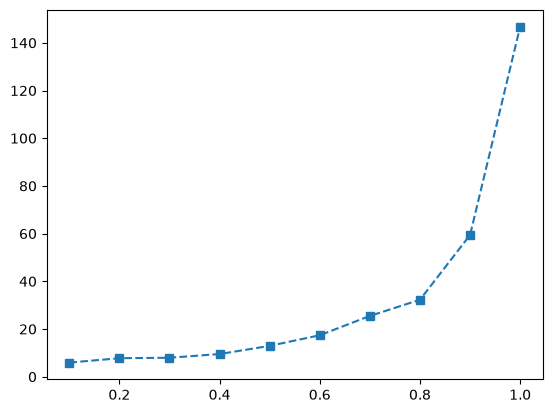

In [9]:
pd.Series(
    pd.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
        "Fare": (
            "count",
            "sum",
            "mean",
            "std",
            "min",
            median,
            "max",
        )
    }).astype(float).round(2)[("Fare", "mean")].values,
    index=np.linspace(0.1, 1, 10)
).plot.line(marker="s", linestyle="--")

In [10]:
pd.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

Fare P20
(-0.001, 7.225]         5.00
(7.225, 7.55]           7.30
(7.55, 7.75]            7.74
(7.75, 7.854]           7.81
(7.854, 7.91]           7.89
(7.91, 8.05]            8.01
(8.05, 9.0]             8.59
(9.0, 10.5]            10.05
(10.5, 13.0]           12.61
(13.0, 14.454]         14.05
(14.454, 16.1]         15.41
(16.1, 21.679]         19.65
(21.679, 26.0]         25.03
(26.0, 27.0]           26.47
(27.0, 31.0]           29.20
(31.0, 39.688]         35.30
(39.688, 56.496]       51.06
(56.496, 77.958]       68.83
(77.958, 112.079]      88.90
(112.079, 512.329]    200.86
Name: (Fare, mean), dtype: float64

<Axes: >

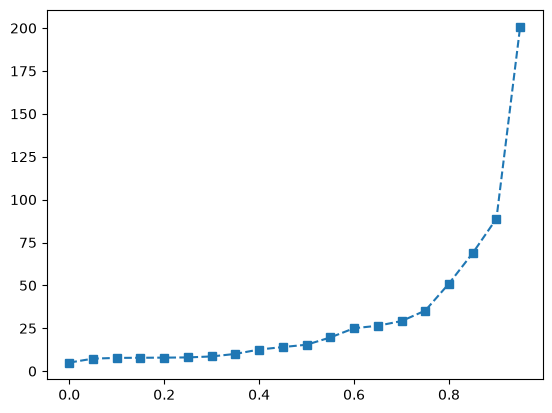

In [11]:
pd.Series(
    pd.DataFrame([c4_q20, c4]).T.groupby("Fare P20").agg({
        "Fare": (
            "count",
            "sum",
            "mean",
            "std",
            "min",
            median,
            "max",
        )
    }).astype(float).round(2)[("Fare", "mean")].values,
    index=np.linspace(0, 1 - 1/20, 20)
).plot.line(marker="s", linestyle="--")

In [12]:
def discretizar_tarifas(tarifa):
    if tarifa > c4.quantile(0.9):
        return "E"
    elif tarifa > c4.quantile(0.8):
        return "D"
    elif tarifa > c4.quantile(0.6):
        return "C"
    elif tarifa > c4.quantile(0.4):
        return "B"
    else:
        return "A"

c4.apply(discretizar_tarifas)

0      A
1      D
2      A
3      D
4      A
      ..
886    B
887    C
888    C
889    C
890    A
Name: Fare, Length: 891, dtype: str

<Axes: ylabel='Fare'>

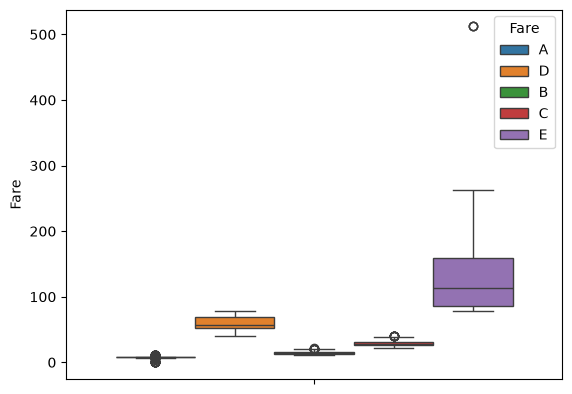

In [13]:
seaborn.boxplot(y=c4, hue=c4.apply(discretizar_tarifas))

In [14]:
cuantiles = pd.DataFrame([c4_q10, c4]).T.groupby("Fare P10").agg({
    "Fare": (
        "count",
        "sum",
        "mean",
        "std",
        "min",
        median,
        "max",
    )
}).astype(float).round(2)[("Fare", "mean")]

cuantiles

Fare P10
(-0.001, 7.55]         5.93
(7.55, 7.854]          7.77
(7.854, 8.05]          7.96
(8.05, 10.5]           9.52
(10.5, 14.454]        12.94
(14.454, 21.679]      17.39
(21.679, 27.0]        25.49
(27.0, 39.688]        32.28
(39.688, 77.958]      59.44
(77.958, 512.329]    146.81
Name: (Fare, mean), dtype: float64

In [15]:
cuantiles.rolling(2).first()

Fare P10
(-0.001, 7.55]         NaN
(7.55, 7.854]         5.93
(7.854, 8.05]         7.77
(8.05, 10.5]          7.96
(10.5, 14.454]        9.52
(14.454, 21.679]     12.94
(21.679, 27.0]       17.39
(27.0, 39.688]       25.49
(39.688, 77.958]     32.28
(77.958, 512.329]    59.44
Name: (Fare, mean), dtype: float64

In [16]:
cuantiles - cuantiles.rolling(2).first()

Fare P10
(-0.001, 7.55]         NaN
(7.55, 7.854]         1.84
(7.854, 8.05]         0.19
(8.05, 10.5]          1.56
(10.5, 14.454]        3.42
(14.454, 21.679]      4.45
(21.679, 27.0]        8.10
(27.0, 39.688]        6.79
(39.688, 77.958]     27.16
(77.958, 512.329]    87.37
Name: (Fare, mean), dtype: float64

In [17]:
diferencia_absoluta = cuantiles - cuantiles.rolling(2).first()
diferencia_absoluta.name = "inc abs"
diferencia_relativa = diferencia_absoluta / cuantiles.rolling(2).first()
diferencia_relativa.name = "% inc rel"

print(diferencia_relativa.quantile(0.5))

cambio_relativo = (diferencia_relativa > diferencia_relativa.quantile(0.5))
cambio_relativo.name = "change"

porcentajes_inf = pd.Series(np.linspace(0, 0.9, 10), index=cuantiles.index) * 100
porcentajes_inf .name = "% inf"

porcentajes_sup = pd.Series(np.linspace(0.1, 1, 10), index=cuantiles.index) * 100
porcentajes_sup .name = "% sup"

pd.DataFrame([porcentajes_inf, porcentajes_sup, cuantiles, 
                  diferencia_absoluta, diferencia_relativa * 100, cambio_relativo]).T

0.3438948995363216


,% inf,% sup,"(Fare, mean)",inc abs,% inc rel,change
Fare P10,,,,,,
"(-0.001, 7.55]",0.0,10.0,5.93,NaN,NaN,0.0
"(7.55, 7.854]",10.0,20.0,7.77,1.84,31.028668,0.0
"(7.854, 8.05]",20.0,30.0,7.96,0.19,2.445302,0.0
"(8.05, 10.5]",30.0,40.0,9.52,1.56,19.597990,0.0
"(10.5, 14.454]",40.0,50.0,12.94,3.42,35.924370,1.0
"(14.454, 21.679]",50.0,60.0,17.39,4.45,34.389490,0.0
"(21.679, 27.0]",60.0,70.0,25.49,8.10,46.578493,1.0
"(27.0, 39.688]",70.0,80.0,32.28,6.79,26.637897,0.0
"(39.688, 77.958]",80.0,90.0,59.44,27.16,84.138786,1.0


In [18]:
def quantiles(serie, n=10, u=0.5):
    serie = serie.copy()
    serie.name = "Value"
    
    q = pd.qcut(serie, q=n)
    q.name = "Quantile"

    median = lambda serie: serie.median()

    cuantiles = pd.DataFrame([q, serie]).T.groupby("Quantile").agg({
        "Value": (
            "count",
            "sum",
            "mean",
            "std",
            "min",
            median,
            "max",
        )
    }).astype(float).round(2)[("Value", "mean")]

    diferencia_absoluta = cuantiles - cuantiles.rolling(2).first()
    diferencia_absoluta.name = "inc abs"
    diferencia_relativa = diferencia_absoluta / cuantiles.rolling(2).first()
    diferencia_relativa.name = "% inc rel"
    
    cambio_relativo = (diferencia_relativa > diferencia_relativa.quantile(u))
    cambio_relativo.name = "change"
    
    porcentajes_inf = pd.Series(np.linspace(0, 1 - 1/n, n), index=cuantiles.index) * 100
    porcentajes_inf .name = "% inf"
    
    porcentajes_sup = pd.Series(np.linspace(1/n, 1, n), index=cuantiles.index) * 100
    porcentajes_sup .name = "% sup"

    grupo = pd.Series(np.arange(1, n + 1), index=cuantiles.index)
    grupo.name = "clu"
    
    return pd.DataFrame([grupo, porcentajes_inf, porcentajes_sup, cuantiles, 
                      diferencia_absoluta, diferencia_relativa * 100, cambio_relativo]).T.astype(float).round(2)

In [19]:
quantiles(c4, n = 20)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(-0.001, 7.225]",1.0,0.0,5.0,5.00,NaN,NaN,0.0
"(7.225, 7.55]",2.0,5.0,10.0,7.30,2.30,46.00,1.0
"(7.55, 7.75]",3.0,10.0,15.0,7.74,0.44,6.03,0.0
"(7.75, 7.854]",4.0,15.0,20.0,7.81,0.07,0.90,0.0
"(7.854, 7.91]",5.0,20.0,25.0,7.89,0.08,1.02,0.0
"(7.91, 8.05]",6.0,25.0,30.0,8.01,0.12,1.52,0.0
"(8.05, 9.0]",7.0,30.0,35.0,8.59,0.58,7.24,0.0
"(9.0, 10.5]",8.0,35.0,40.0,10.05,1.46,17.00,0.0
"(10.5, 13.0]",9.0,40.0,45.0,12.61,2.56,25.47,1.0


In [20]:
quantiles(c7, n = 20, u=0.50)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(0.419, 4.0]",1.0,0.0,5.0,2.25,NaN,NaN,0.0
"(4.0, 14.0]",2.0,5.0,10.0,9.43,7.18,319.11,1.0
"(14.0, 17.0]",3.0,10.0,15.0,16.18,6.75,71.58,1.0
"(17.0, 19.0]",4.0,15.0,20.0,18.49,2.31,14.28,1.0
"(19.0, 20.125]",5.0,20.0,25.0,20.00,1.51,8.17,1.0
"(20.125, 22.0]",6.0,25.0,30.0,21.51,1.51,7.55,0.0
"(22.0, 24.0]",7.0,30.0,35.0,23.66,2.15,10.00,1.0
"(24.0, 25.0]",8.0,35.0,40.0,24.98,1.32,5.58,0.0
"(25.0, 27.0]",9.0,40.0,45.0,26.50,1.52,6.08,0.0


In [21]:
quantiles(c7, n = 5, u=0.75)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(0.419, 19.0]",1.0,0.0,20.0,11.98,NaN,NaN,0.0
"(19.0, 25.0]",2.0,20.0,40.0,22.68,10.70,89.32,1.0
"(25.0, 31.8]",3.0,40.0,60.0,28.57,5.89,25.97,0.0
"(31.8, 41.0]",4.0,60.0,80.0,35.92,7.35,25.73,0.0
"(41.0, 80.0]",5.0,80.0,100.0,51.64,15.72,43.76,0.0


## 2. Reporte discreto (soportes y proporciones)

In [22]:
x1 = c1
x2 = c2
x3 = c3
x4 = c5
x5 = c6
x6 = pd.qcut(c4, q=[0, 0.1, 0.45, 0.6, 0.65, 0.8, 1], labels=[f"fare-{g}" for g in np.arange(1, 7)])
x7 = pd.qcut(c7, q=[0, 0.15, 0.35, 0.66, 0.8, 1], labels=[f"age-{g}" for g in np.arange(1, 6)])
x8 = pd.cut(c8, bins=[-1, 0.5, 1.5, 2.5, c8.max()], labels=[f"famh-{g}" for g in np.arange(0, 4)])
x9 = pd.cut(c9, bins=[-1, 0.5, 1.5, 2.5, c9.max()], labels=[f"famv-{g}" for g in np.arange(0, 4)])

X = pd.DataFrame([x1, x2, x3, x4, x5, x6, x7, x8, x9]).T

X

,Survived,Sex,Pclass,Cabin,Embarked,Fare,Age,SibSp,Parch
0,no,male,3rd,no,southampton,fare-1,age-2,famh-1,famv-0
1,yes,female,1st,yes,cherbug,fare-6,age-4,famh-1,famv-0
2,yes,female,3rd,no,southampton,fare-2,age-3,famh-0,famv-0
3,yes,female,1st,yes,southampton,fare-6,age-4,famh-1,famv-0
4,no,male,3rd,no,southampton,fare-2,age-4,famh-0,famv-0
...,...,...,...,...,...,...,...,...,...
886,no,male,2nd,no,southampton,fare-2,age-3,famh-0,famv-0
887,yes,female,1st,yes,southampton,fare-5,age-2,famh-0,famv-0
888,no,female,3rd,no,southampton,fare-4,NaN,famh-1,famv-2
889,yes,male,1st,yes,cherbug,fare-5,age-3,famh-0,famv-0


In [23]:
# 1-Característica vs Respuesta (Probabilidad simple)

# Formato largo -> Índice combina todas las posibilidades
X[["Sex", "Survived"]].groupby(["Sex", "Survived"]).size() # Soportes

Sex     Survived
female  no           81
        yes         233
male    no          468
        yes         109
dtype: int64

<Axes: ylabel='Sex,Survived'>

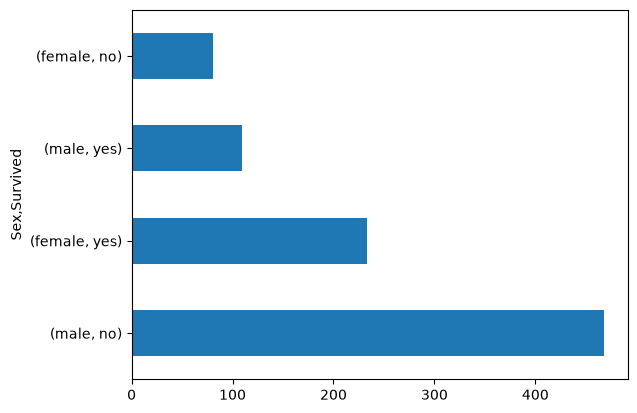

In [24]:
X[["Sex", "Survived"]].groupby(["Sex", "Survived"]).size().sort_values(ascending=False).plot.barh()

In [25]:
# Formato ancho -> Desglosa las combinaciones de la última variable (Survived)
M = X[["Sex", "Survived"]].groupby(["Sex", "Survived"]).size().unstack()

M

Survived,no,yes
Sex,,
female,81,233
male,468,109


<Axes: xlabel='Survived', ylabel='Sex'>

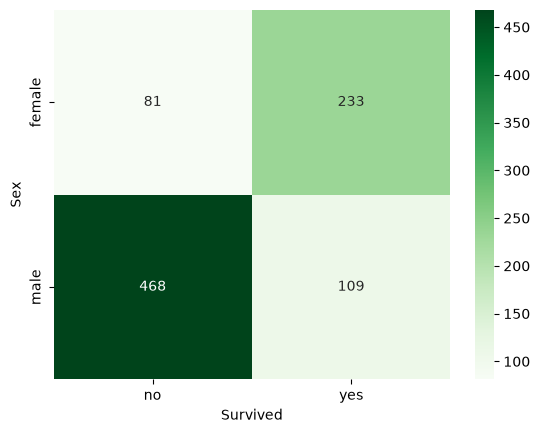

In [26]:
seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".0f") # Ubicamos el mayor soporte global

- MUJER + NO SOBREVIVE  : 81    - Los casos menos frecuentes son 81 mujeres que no sobreviven
- HOMBRE + SOBREVIVE    : 109   - Le siguen 109 hombres que sobreviven
- MUJER + SOBREVIVE     : 233   - Mientras que 233 mujeres si sobreviven
- HOMBRE + NO SOBREVIVE : 468   - Y la mayoría (468) hombres no sobreviven

In [27]:
R1 = M.divide(M.sum(axis=1), axis=0)

R1

Survived,no,yes
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


Text(0.5, 1.0, 'Proporción de la supervivencia por cada sexo')

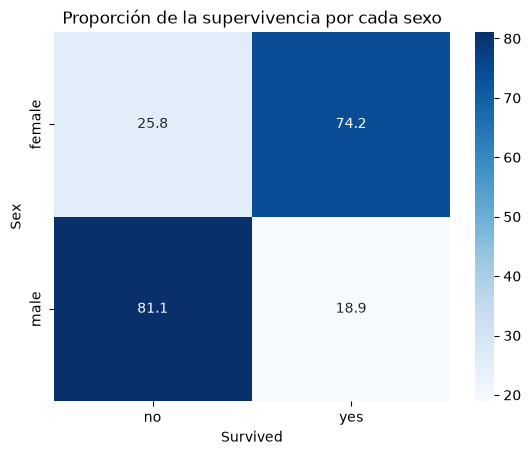

In [28]:
seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f")
pyplot.title("Proporción de la supervivencia por cada sexo")

- MUJER + NO SOBREVIVE  : 26%    - En las mujeres 26% no sobreviven
- MUJER + SOBREVIVE     : 74%    - Mientras que 74% si sobrevive
- HOMBRE + NO SOBREVIVE : 81%    - En los hombres 81% no sobreviven
- HOMBRE + SOBREVIVE    : 19%    - Mientras que 19% si sobrevive

1. P(NO SOBREVIVE | MUJER) = 0.258
2. P(SOBREVIVE | MUJER) = 0.742
3. P(NO SOBREVIVE | HOMBRE) = 0.811
4. P(SOBREVIVE | HOMBRE) = 0.189

In [29]:
R2 = M.divide(M.sum(axis=0), axis=1)

R2

Survived,no,yes
Sex,,
female,0.147541,0.681287
male,0.852459,0.318713


Text(0.5, 1.0, 'Proporción de hombres y mujeres por cada tipo de supervivencia')

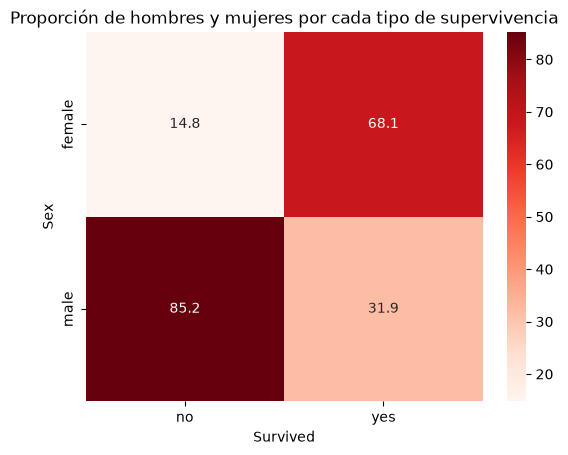

In [30]:
seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f")
pyplot.title("Proporción de hombres y mujeres por cada tipo de supervivencia")

- NO SOBREVIVE + MUJER  : 14.8%    - De los que no sobreviven 14.8% son mujeres
- NO SOBREVIVE + HOMBRE : 85.2%    - Mientras que 85.2% hombres
- SOBREVIVE + MUJER     : 68.1%    - De los que si sobreviven 68.1% son mujeres
- SOBREVIVE + HOMBRE    : 31.9%    - Mientras que 31.9% son hombres

1. P(MUJER | NO SOBREVIVE) = 0.148
2. P(HOMBRE | NO SOBREVIVE) = 0.852
3. P(MUJER | SOBREVIVE) = 0.681
4. P(HOMBRE | SOBREVIVE) = 0.319

Soporte      % Horizontales       % Verticales      
Survived      no  yes             no   yes           no   yes
Sex                                                          
female        81  233           25.8  74.2         14.8  68.1
male         468  109           81.1  18.9         85.2  31.9

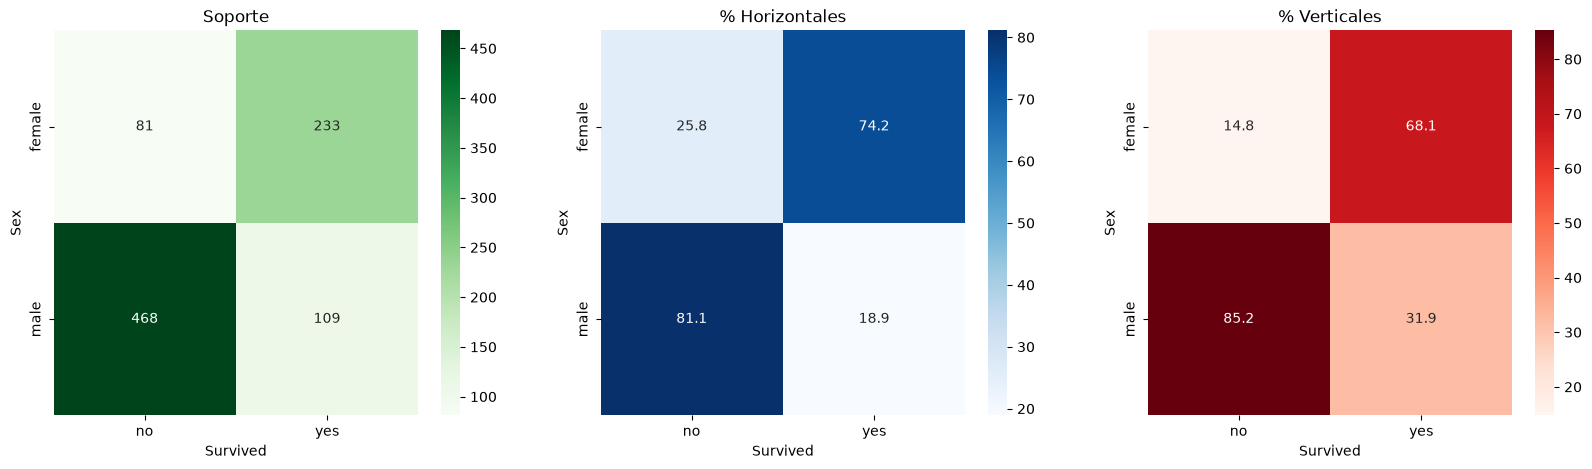

In [31]:
# Creando una función para lo anterior

def reporte_discreto_simple(X, a, b, plot=True):
    x = X[a]
    y = X[b]

    M = pd.DataFrame([x, y]).T.groupby([a, b]).size().unstack()
    R1 = M.divide(M.sum(axis=1), axis=0)
    R2 = M.divide(M.sum(axis=0), axis=1)

    if plot:
        figure, axis = pyplot.subplots(1, 3, figsize=(20, 5))
        axis[0].set_title("Soporte")
        seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".0f", ax=axis[0])
        axis[1].set_title("% Horizontales")
        seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
        axis[2].set_title("% Verticales")
        seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])

    return pd.concat([M, 100 * R1, 100 * R2], axis=1, 
                         keys=["Soporte", "% Horizontales", "% Verticales"],).round(1)

reporte_discreto_simple(X, "Sex", "Survived")

Soporte      % Horizontales       % Verticales      
Survived      no  yes             no   yes           no   yes
Pclass                                                       
1st           80  136           37.0  63.0         14.6  39.8
2nd           97   87           52.7  47.3         17.7  25.4
3rd          372  119           75.8  24.2         67.8  34.8

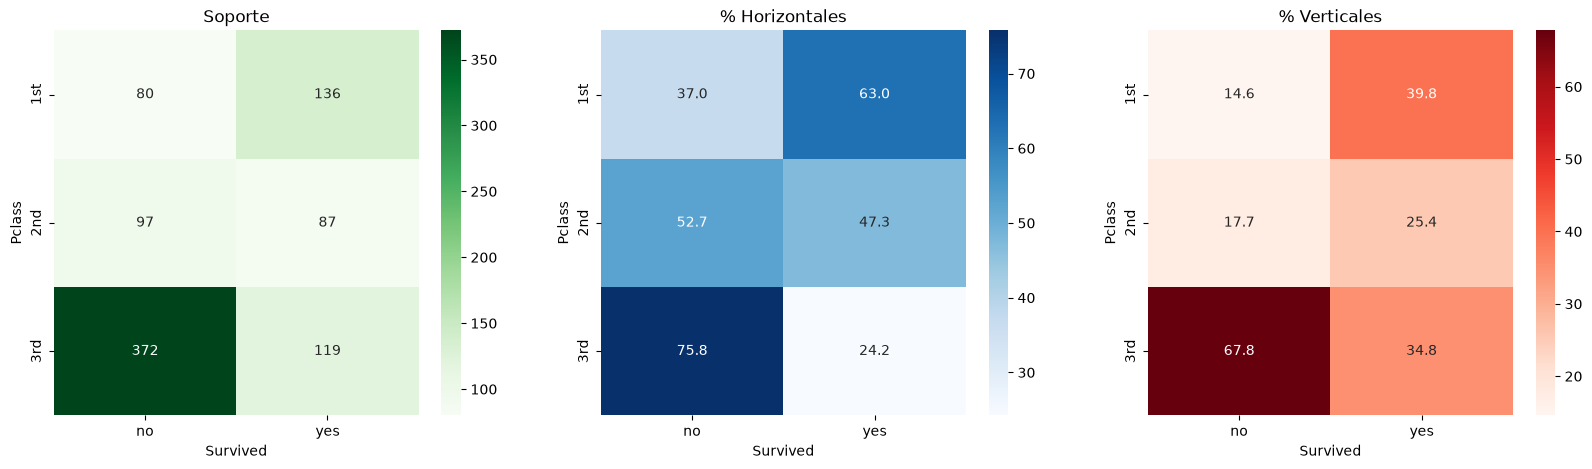

In [32]:
reporte_discreto_simple(X, "Pclass", "Survived")

Soporte      % Horizontales       % Verticales      
Survived      no  yes             no   yes           no   yes
Fare                                                         
fare-1        79   13           85.9  14.1         14.4   3.8
fare-2       243   93           72.3  27.7         44.3  27.2
fare-3        64   43           59.8  40.2         11.7  12.6
fare-4        33   28           54.1  45.9          6.0   8.2
fare-5        67   52           56.3  43.7         12.2  15.2
fare-6        63  113           35.8  64.2         11.5  33.0

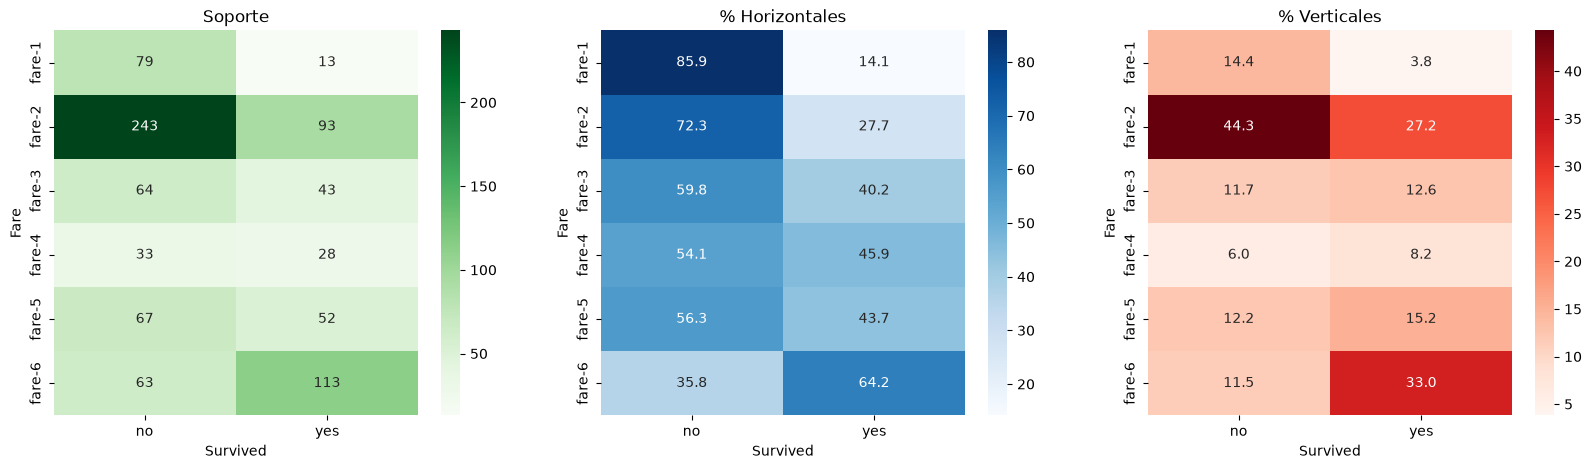

In [33]:
reporte_discreto_simple(X, "Fare", "Survived")

Soporte     % Horizontales       % Verticales      
Survived      no yes             no   yes           no   yes
Age                                                         
age-1         52  61           46.0  54.0         12.3  21.0
age-2        107  57           65.2  34.8         25.2  19.7
age-3        123  78           61.2  38.8         29.0  26.9
age-4         53  41           56.4  43.6         12.5  14.1
age-5         89  53           62.7  37.3         21.0  18.3

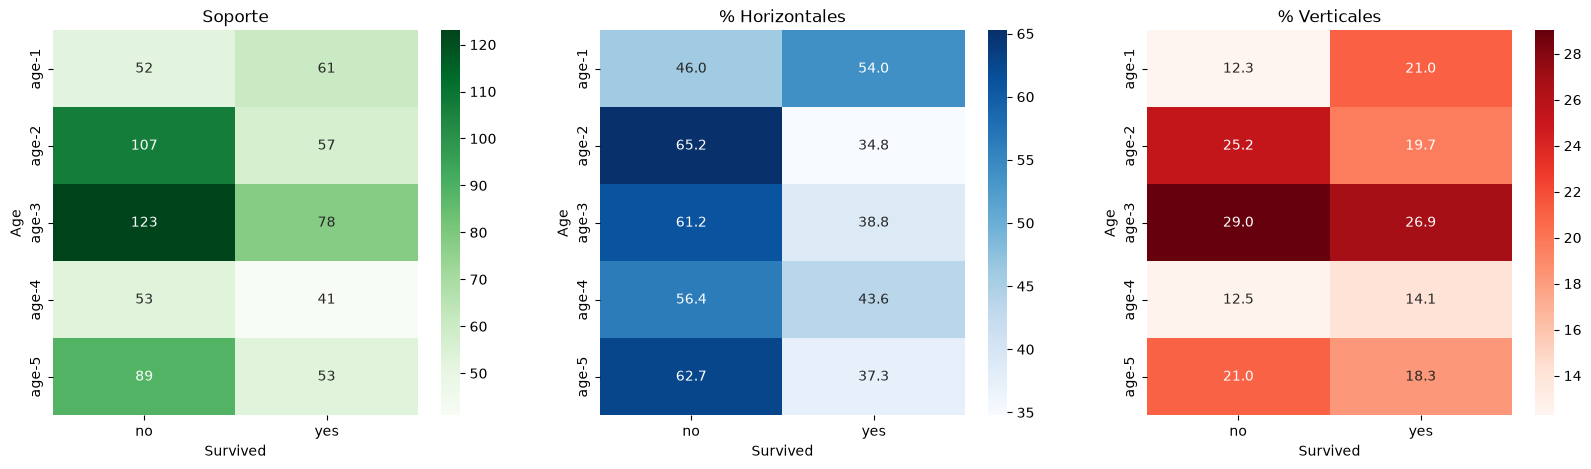

In [34]:
reporte_discreto_simple(X, "Age", "Survived")

In [35]:
quantiles(c7, n = 5)

,clu,% inf,% sup,"(Value, mean)",inc abs,% inc rel,change
Quantile,,,,,,,
"(0.419, 19.0]",1.0,0.0,20.0,11.98,NaN,NaN,0.0
"(19.0, 25.0]",2.0,20.0,40.0,22.68,10.70,89.32,1.0
"(25.0, 31.8]",3.0,40.0,60.0,28.57,5.89,25.97,0.0
"(31.8, 41.0]",4.0,60.0,80.0,35.92,7.35,25.73,0.0
"(41.0, 80.0]",5.0,80.0,100.0,51.64,15.72,43.76,1.0


In [36]:
X[["Age", "Sex", "Survived"]].groupby(["Age", "Sex", "Survived"]).size()

Age    Sex     Survived
age-1  female  no           17
               yes          38
       male    no           35
               yes          23
age-2  female  no           15
               yes          47
       male    no           92
               yes          10
age-3  female  no           16
               yes          47
       male    no          107
               yes          31
age-4  female  no            7
               yes          30
       male    no           46
               yes          11
age-5  female  no            9
               yes          35
       male    no           80
               yes          18
dtype: int64

In [37]:
# 2-Características vs Respuesta
X[["Age", "Sex", "Survived"]].groupby(["Age", "Sex", "Survived"]).size().unstack() # En un formato de tabla más visual

Survived       no  yes
Age   Sex             
age-1 female   17   38
      male     35   23
age-2 female   15   47
      male     92   10
age-3 female   16   47
      male    107   31
age-4 female    7   30
      male     46   11
age-5 female    9   35
      male     80   18

In [38]:
# Agrupando por clase
X[["Age", "Sex", "Pclass", "Survived"]].groupby(["Age", "Sex", "Pclass", "Survived"]).size().unstack()

Survived               no   yes
Age   Sex    Pclass            
age-1 female 1st      1.0   7.0
             2nd      NaN  12.0
             3rd     16.0  19.0
      male   1st      NaN   4.0
             2nd      2.0   9.0
             3rd     33.0  10.0
age-2 female 1st      NaN  19.0
             2nd      1.0  14.0
             3rd     14.0  14.0
      male   1st      7.0   1.0
             2nd     19.0   1.0
             3rd     66.0   8.0
age-3 female 1st      1.0  13.0
             2nd      2.0  24.0
             3rd     13.0  10.0
      male   1st      9.0  11.0
             2nd     33.0   3.0
             3rd     65.0  17.0
age-4 female 1st      NaN  19.0
             2nd      1.0   8.0
             3rd      6.0   3.0
      male   1st      9.0  10.0
             2nd     11.0   NaN
             3rd     26.0   1.0
age-5 female 1st      1.0  24.0
             2nd      2.0  10.0
             3rd      6.0   1.0
      male   1st     36.0  14.0
             2nd     19.0   2.0
             3rd     25.0   2.0

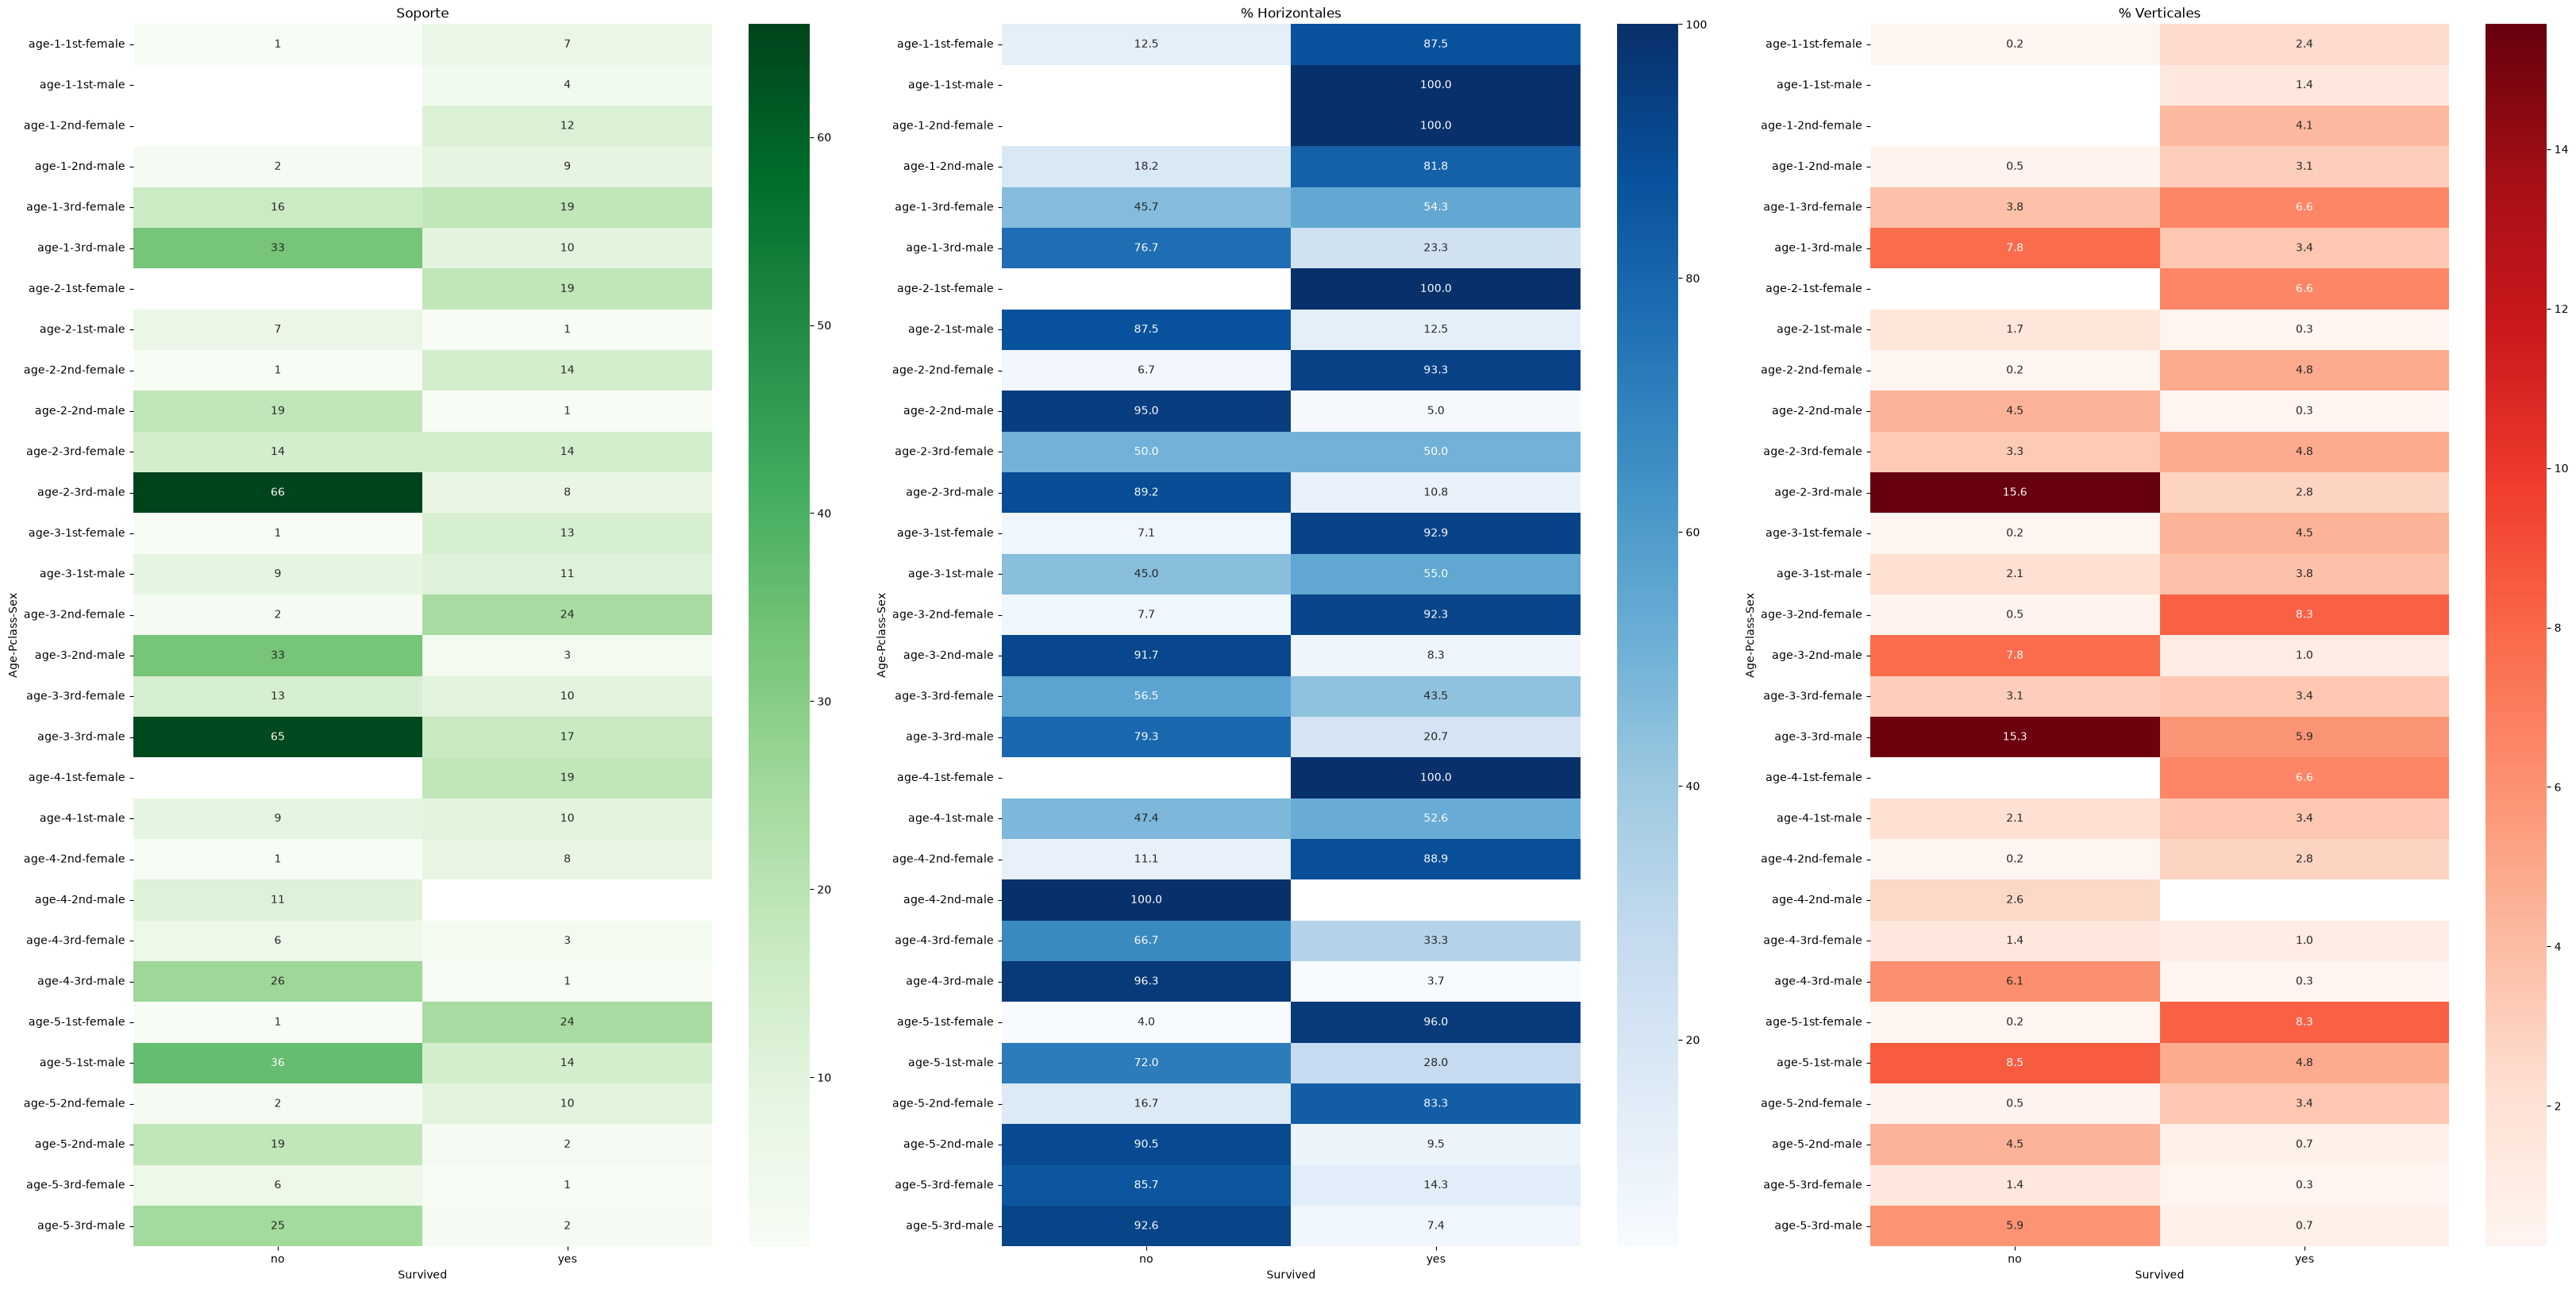

Soporte       % Horizontales        % Verticales     
Survived                 no   yes             no    yes           no  yes
Age   Pclass Sex                                                         
age-1 1st    female     1.0   7.0           12.5   87.5          0.2  2.4
             male       NaN   4.0            NaN  100.0          NaN  1.4
      2nd    female     NaN  12.0            NaN  100.0          NaN  4.1
             male       2.0   9.0           18.2   81.8          0.5  3.1
      3rd    female    16.0  19.0           45.7   54.3          3.8  6.6
             male      33.0  10.0           76.7   23.3          7.8  3.4
age-2 1st    female     NaN  19.0            NaN  100.0          NaN  6.6
             male       7.0   1.0           87.5   12.5          1.7  0.3
      2nd    female     1.0  14.0            6.7   93.3          0.2  4.8
             male      19.0   1.0           95.0    5.0          4.5  0.3
      3rd    female    14.0  14.0           50.0   50.0          3.3  4.8
             male      66.0   8.0           89.2   10.8         15.6  2.8
age-3 1st    female     1.0  13.0            7.1   92.9          0.2  4.5
             male       9.0  11.0           45.0   55.0          2.1  3.8
      2nd    female     2.0  24.0            7.7   92.3          0.5  8.3
             male      33.0   3.0           91.7    8.3          7.8  1.0
      3rd    female    13.0  10.0           56.5   43.5          3.1  3.4
             male      65.0  17.0           79.3   20.7         15.3  5.9
age-4 1st    female     NaN  19.0            NaN  100.0          NaN  6.6
             male       9.0  10.0           47.4   52.6          2.1  3.4
      2nd    female     1.0   8.0           11.1   88.9          0.2  2.8
             male      11.0   NaN          100.0    NaN          2.6  NaN
      3rd    female     6.0   3.0           66.7   33.3          1.4  1.0
             male      26.0   1.0           96.3    3.7          6.1  0.3
age-5 1st    female     1.0  24.0            4.0   96.0          0.2  8.3
             male      36.0  14.0           72.0   28.0          8.5  4.8
      2nd    female     2.0  10.0           16.7   83.3          0.5  3.4
             male      19.0   2.0           90.5    9.5          4.5  0.7
      3rd    female     6.0   1.0           85.7   14.3          1.4  0.3
             male      25.0   2.0           92.6    7.4          5.9  0.7

In [39]:
# Retomando la función anterior, para multi-índices
def reporte_discreto_multiple(X, clases, respuesta, plot=True, nombre="reporte.png"):
    x = X[clases]
    y = X[respuesta]

    M = X[clases].join(X[respuesta]).groupby(clases + [respuesta]).size().unstack()
    R1 = M.divide(M.sum(axis=1), axis=0)
    R2 = M.divide(M.sum(axis=0), axis=1)

    if plot:
        figure, axis = pyplot.subplots(1, 3, figsize=(40, 20))
        axis[0].set_title("Soporte")
        seaborn.heatmap(M, cmap="Greens", annot=True, fmt=".0f", ax=axis[0])
        axis[1].set_title("% Horizontales")
        seaborn.heatmap(100 * R1, cmap="Blues", annot=True, fmt=".1f", ax=axis[1])
        axis[2].set_title("% Verticales")
        seaborn.heatmap(100 * R2, cmap="Reds", annot=True, fmt=".1f", ax=axis[2])
        figure.savefig(nombre, dpi=300)
        pyplot.show()

    return pd.concat([M, 100 * R1, 100 * R2], axis=1, 
                         keys=["Soporte", "% Horizontales", "% Verticales"],).round(1)

reporte_discreto_multiple(X, ["Age", "Pclass", "Sex"], "Survived")

In [40]:
clases = ["Age", "Pclass", "Sex"]
respuesta = "Survived"

X[clases].join(X[respuesta]).groupby(clases + [respuesta]).size().unstack()

Survived               no   yes
Age   Pclass Sex               
age-1 1st    female   1.0   7.0
             male     NaN   4.0
      2nd    female   NaN  12.0
             male     2.0   9.0
      3rd    female  16.0  19.0
             male    33.0  10.0
age-2 1st    female   NaN  19.0
             male     7.0   1.0
      2nd    female   1.0  14.0
             male    19.0   1.0
      3rd    female  14.0  14.0
             male    66.0   8.0
age-3 1st    female   1.0  13.0
             male     9.0  11.0
      2nd    female   2.0  24.0
             male    33.0   3.0
      3rd    female  13.0  10.0
             male    65.0  17.0
age-4 1st    female   NaN  19.0
             male     9.0  10.0
      2nd    female   1.0   8.0
             male    11.0   NaN
      3rd    female   6.0   3.0
             male    26.0   1.0
age-5 1st    female   1.0  24.0
             male    36.0  14.0
      2nd    female   2.0  10.0
             male    19.0   2.0
      3rd    female   6.0   1.0
             male    25.0   2.0

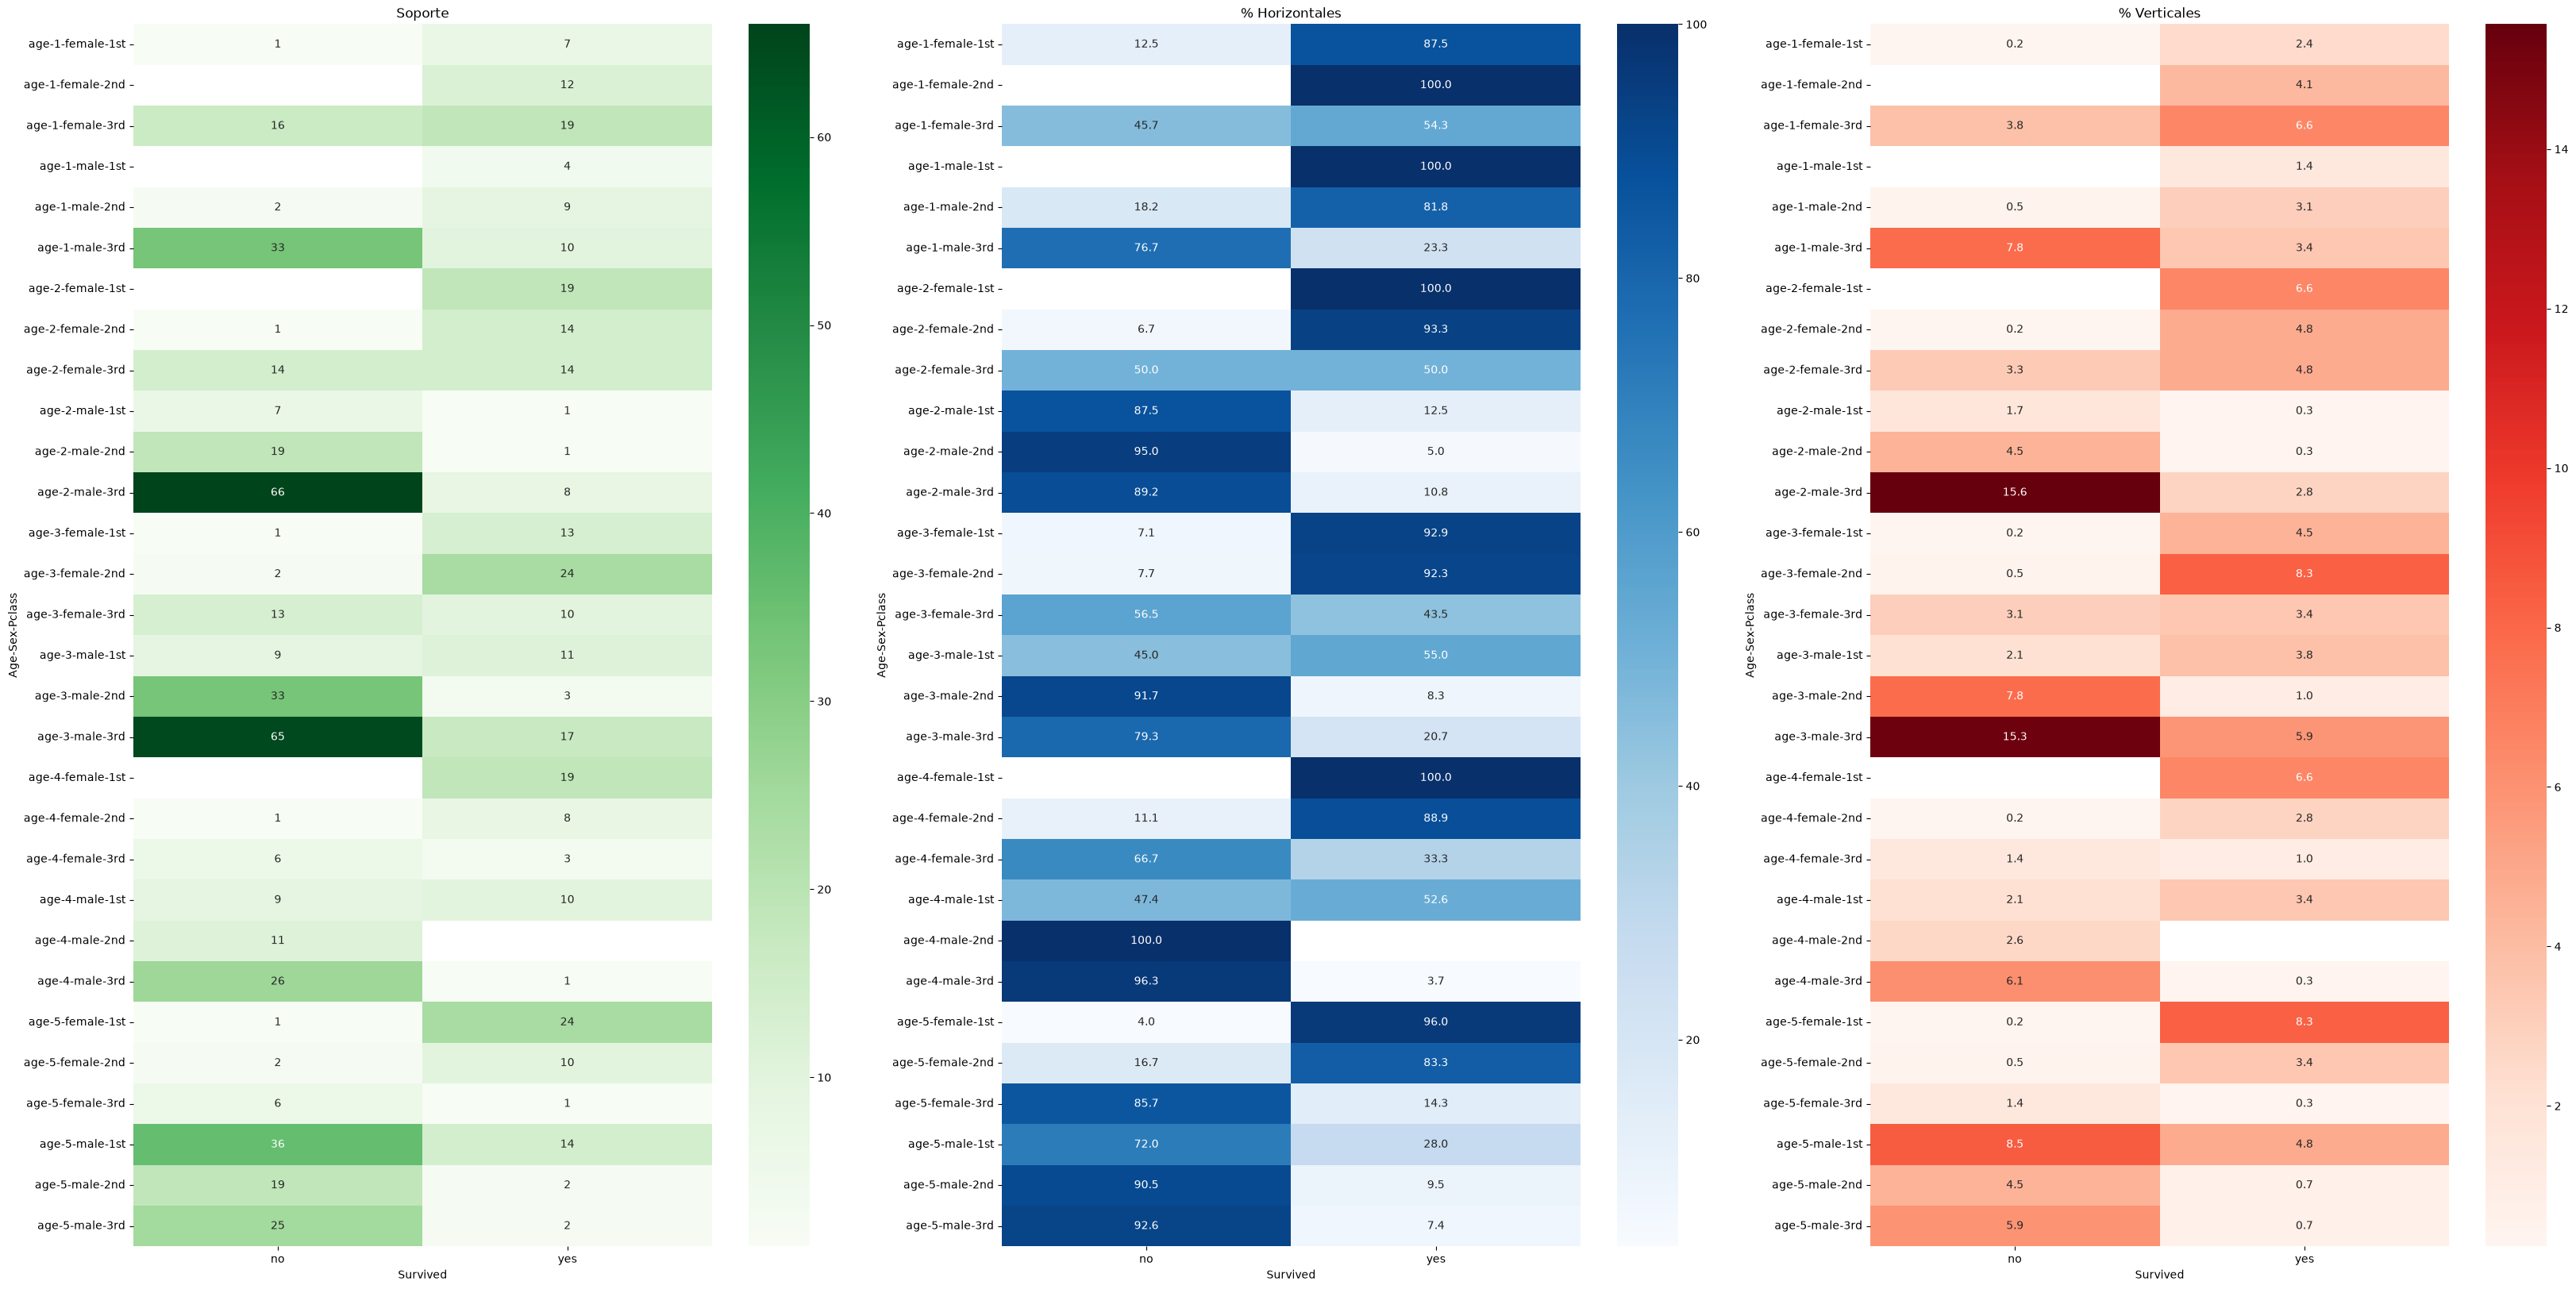

Soporte       % Horizontales        % Verticales     
Survived                 no   yes             no    yes           no  yes
Age   Sex    Pclass                                                      
age-1 female 1st        1.0   7.0           12.5   87.5          0.2  2.4
             2nd        NaN  12.0            NaN  100.0          NaN  4.1
             3rd       16.0  19.0           45.7   54.3          3.8  6.6
      male   1st        NaN   4.0            NaN  100.0          NaN  1.4
             2nd        2.0   9.0           18.2   81.8          0.5  3.1
             3rd       33.0  10.0           76.7   23.3          7.8  3.4
age-2 female 1st        NaN  19.0            NaN  100.0          NaN  6.6
             2nd        1.0  14.0            6.7   93.3          0.2  4.8
             3rd       14.0  14.0           50.0   50.0          3.3  4.8
      male   1st        7.0   1.0           87.5   12.5          1.7  0.3
             2nd       19.0   1.0           95.0    5.0          4.5  0.3
             3rd       66.0   8.0           89.2   10.8         15.6  2.8
age-3 female 1st        1.0  13.0            7.1   92.9          0.2  4.5
             2nd        2.0  24.0            7.7   92.3          0.5  8.3
             3rd       13.0  10.0           56.5   43.5          3.1  3.4
      male   1st        9.0  11.0           45.0   55.0          2.1  3.8
             2nd       33.0   3.0           91.7    8.3          7.8  1.0
             3rd       65.0  17.0           79.3   20.7         15.3  5.9
age-4 female 1st        NaN  19.0            NaN  100.0          NaN  6.6
             2nd        1.0   8.0           11.1   88.9          0.2  2.8
             3rd        6.0   3.0           66.7   33.3          1.4  1.0
      male   1st        9.0  10.0           47.4   52.6          2.1  3.4
             2nd       11.0   NaN          100.0    NaN          2.6  NaN
             3rd       26.0   1.0           96.3    3.7          6.1  0.3
age-5 female 1st        1.0  24.0            4.0   96.0          0.2  8.3
             2nd        2.0  10.0           16.7   83.3          0.5  3.4
             3rd        6.0   1.0           85.7   14.3          1.4  0.3
      male   1st       36.0  14.0           72.0   28.0          8.5  4.8
             2nd       19.0   2.0           90.5    9.5          4.5  0.7
             3rd       25.0   2.0           92.6    7.4          5.9  0.7

In [41]:
reporte_discreto_multiple(X, ["Age", "Sex", "Pclass"], "Survived")

## 3. Reporte discretizado (razonamiento)

In [42]:
q = quantiles(c4, n = 6)
s = reporte_discreto_simple(X, "Fare", "Survived", plot=False)

x = q[("Value", "mean")].values
y = s[("% Horizontales", "yes")].values

pd.DataFrame([x, y]).T

,0,1
0,6.67,14.1
1,8.03,27.7
2,11.75,40.2
3,20.52,45.9
4,34.13,43.7
5,112.48,64.2


In [43]:
! python -m pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip


<Axes: >

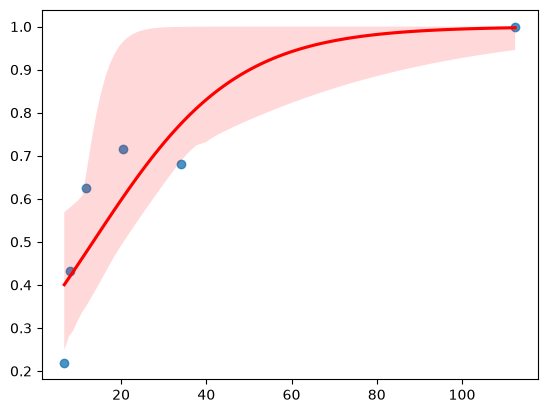

In [44]:
seaborn.regplot(x=x, y=y / y.max(), logistic=True, line_kws={"color": "red"})

In [45]:
60, y.max() * 0.95

(60, np.float64(60.99))

In [46]:
40, y.max() * 0.81

(40, np.float64(52.002))

## 4. Reporte cruzado (inferencia a la respuesta)

In [47]:
P = reporte_discreto_multiple(X, ["Sex", "Cabin"], "Survived", plot=False)

P

Soporte      % Horizontales       % Verticales      
Survived          no  yes             no   yes           no   yes
Sex    Cabin                                                     
female no         75  142           34.6  65.4         13.7  41.5
       yes         6   91            6.2  93.8          1.1  26.6
male   no        406   64           86.4  13.6         74.0  18.7
       yes        62   45           57.9  42.1         11.3  13.2

In [48]:
# P(MUJER ^ NO CABINA | SOBREVIVE) = 41.5%

P.loc[("female", "no"), ("% Verticales", "yes")]

np.float64(41.5)

In [49]:
# P(SOBREVIVE | MUJER ^ NO CABINA) = 65.4%

P.loc[("female", "no"), ("% Horizontales", "yes")]

np.float64(65.4)

In [53]:
# P(SOBREVIVE | HOMBRE ^ 1RA ^ EDAD-NIÑOS) = ? -> 100%

P = reporte_discreto_multiple(X, ["Sex", "Pclass", "Age"], "Survived", plot=False)

P.loc[("male", "1st", "age-1"), ("% Horizontales", "yes")]

np.float64(100.0)

In [51]:
P.loc[("male", "3rd", "age-1"), ("% Horizontales", "yes")]

np.float64(23.3)

### Ejercicio - Producir una inferencia en múltiples condiciones

In [58]:
X.describe()

,Survived,Sex,Pclass,Cabin,Embarked,Fare,Age,SibSp,Parch
count,891,891,891,891,889,891,714,891,891
unique,2,2,3,2,3,6,5,4,4
top,no,male,3rd,no,southampton,fare-2,age-3,famh-0,famv-0
freq,549,577,491,687,644,336,201,608,678


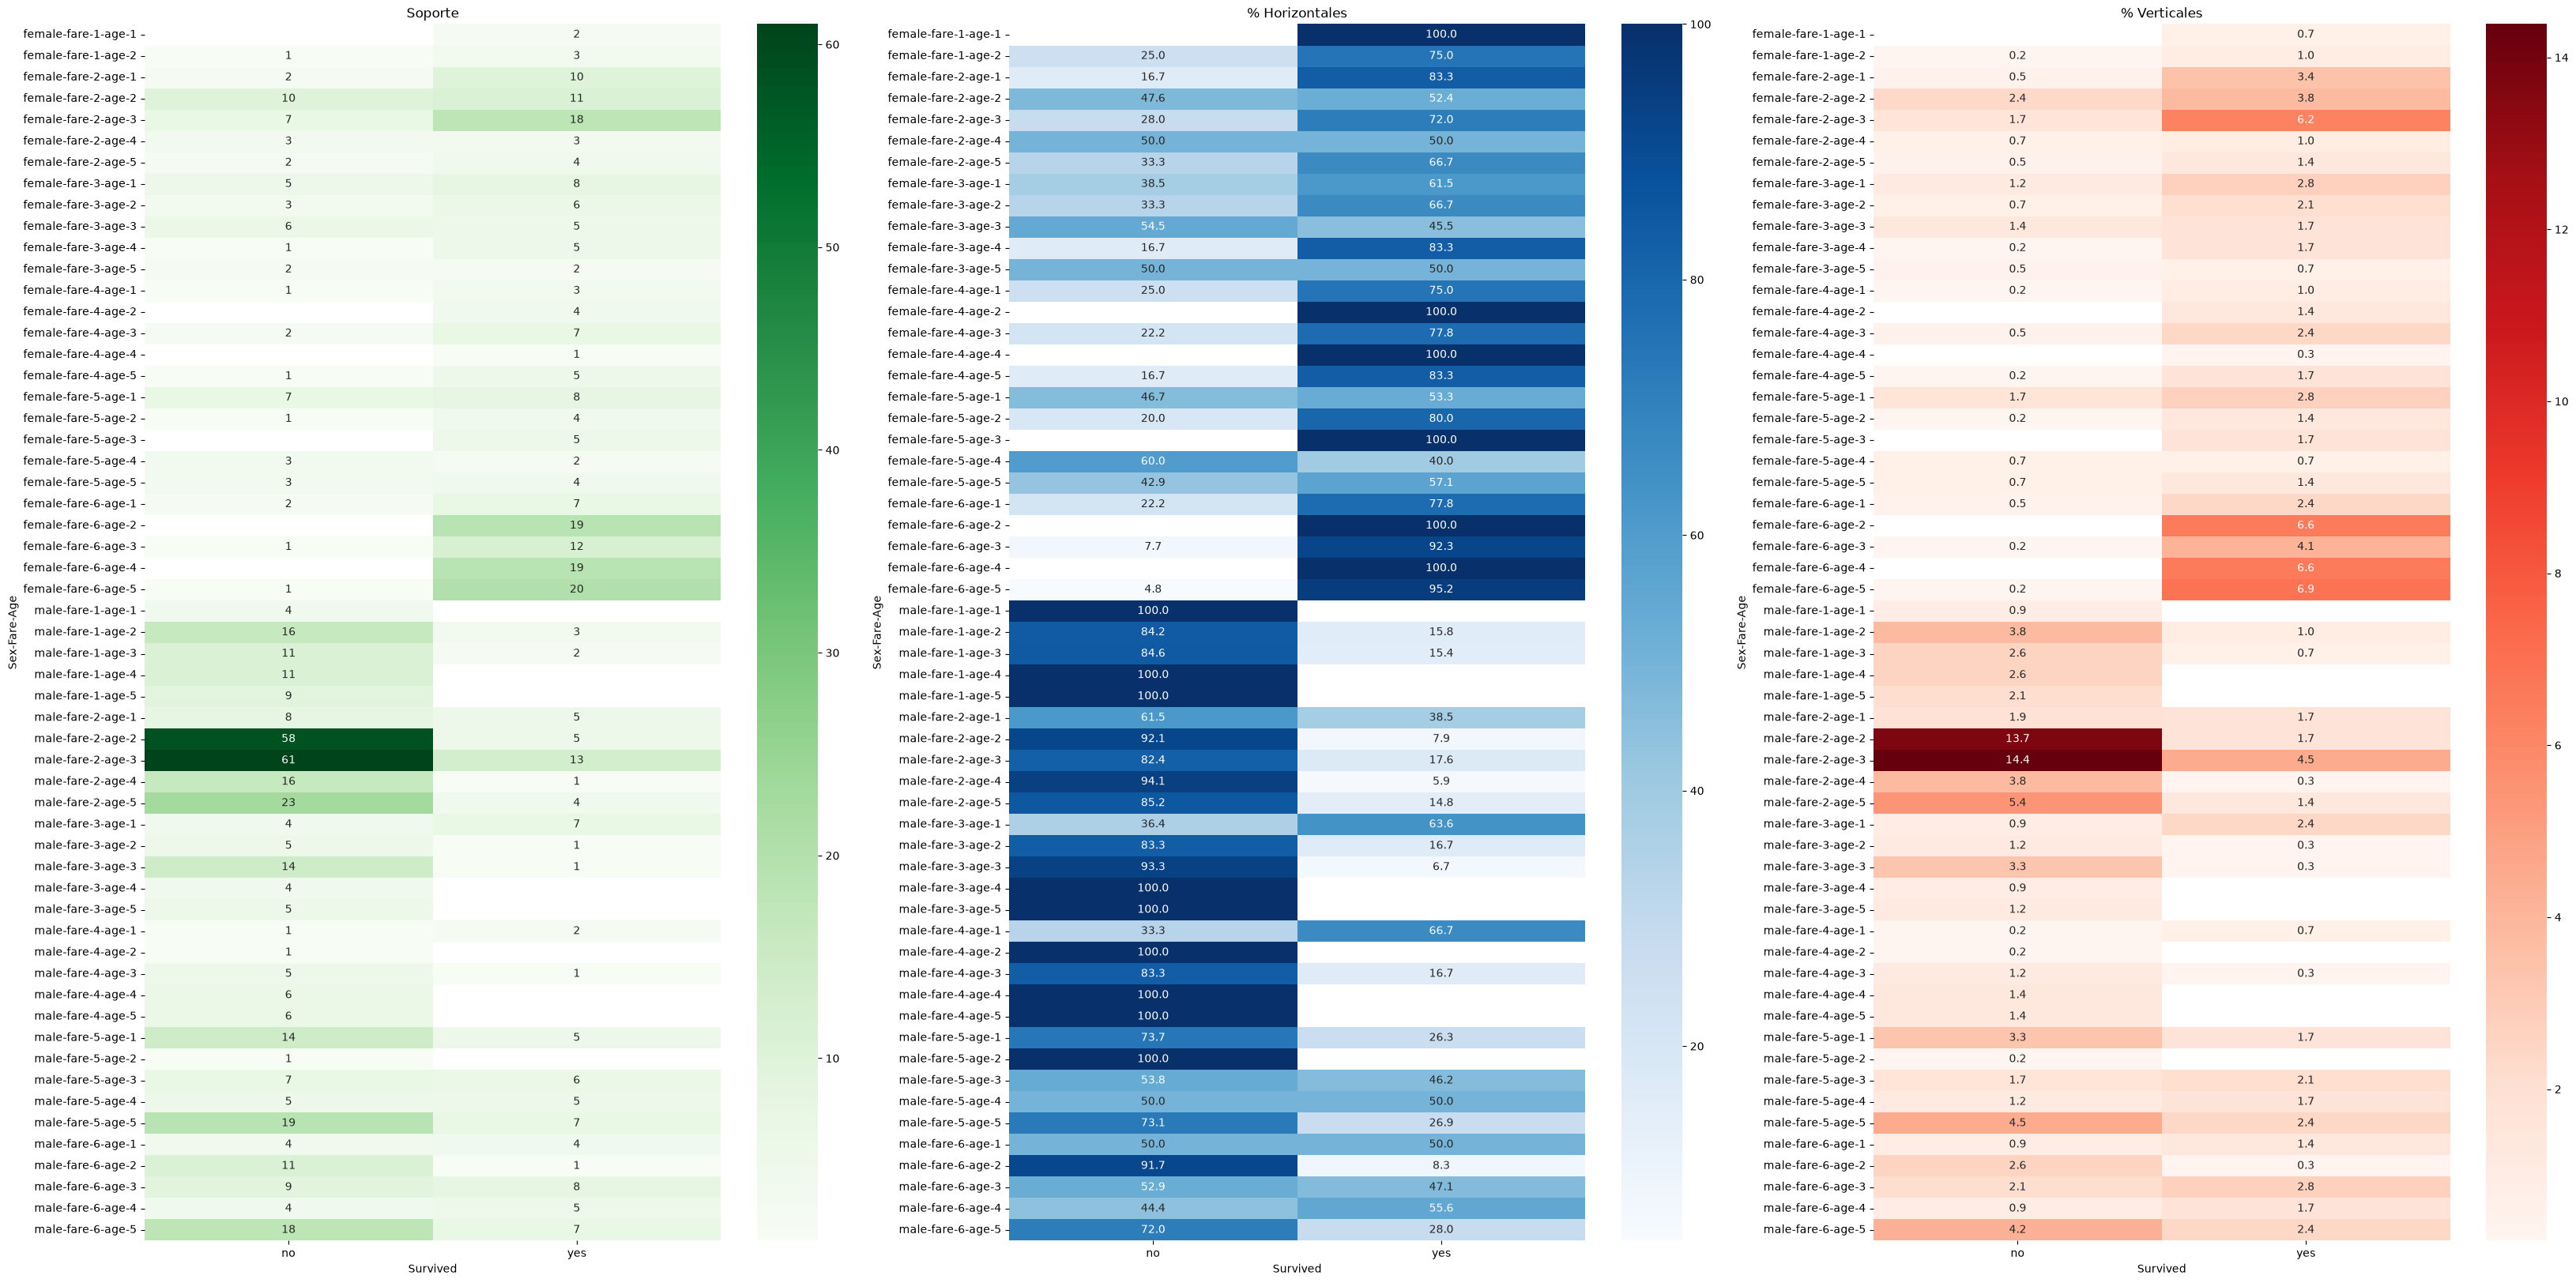

In [57]:
P_ejer = reporte_discreto_multiple(X, ["Sex", "Fare", "Age"], "Survived")

In [60]:
# P(SOBREVIVE | HOMBRE ^ TARIFA MUY ALTA ^ EDAD MUY ALTA) = 28%

P_ejer.loc[("male", "fare-6", "age-5"), ("% Horizontales", "yes")]

np.float64(28.0)

In [61]:
# P(SOBREVIVE | MUJER ^ TARIFA MUY ALTA ^ EDAD MUY ALTA) = 95.2%

P_ejer.loc[("female", "fare-6", "age-5"), ("% Horizontales", "yes")]

np.float64(95.2)

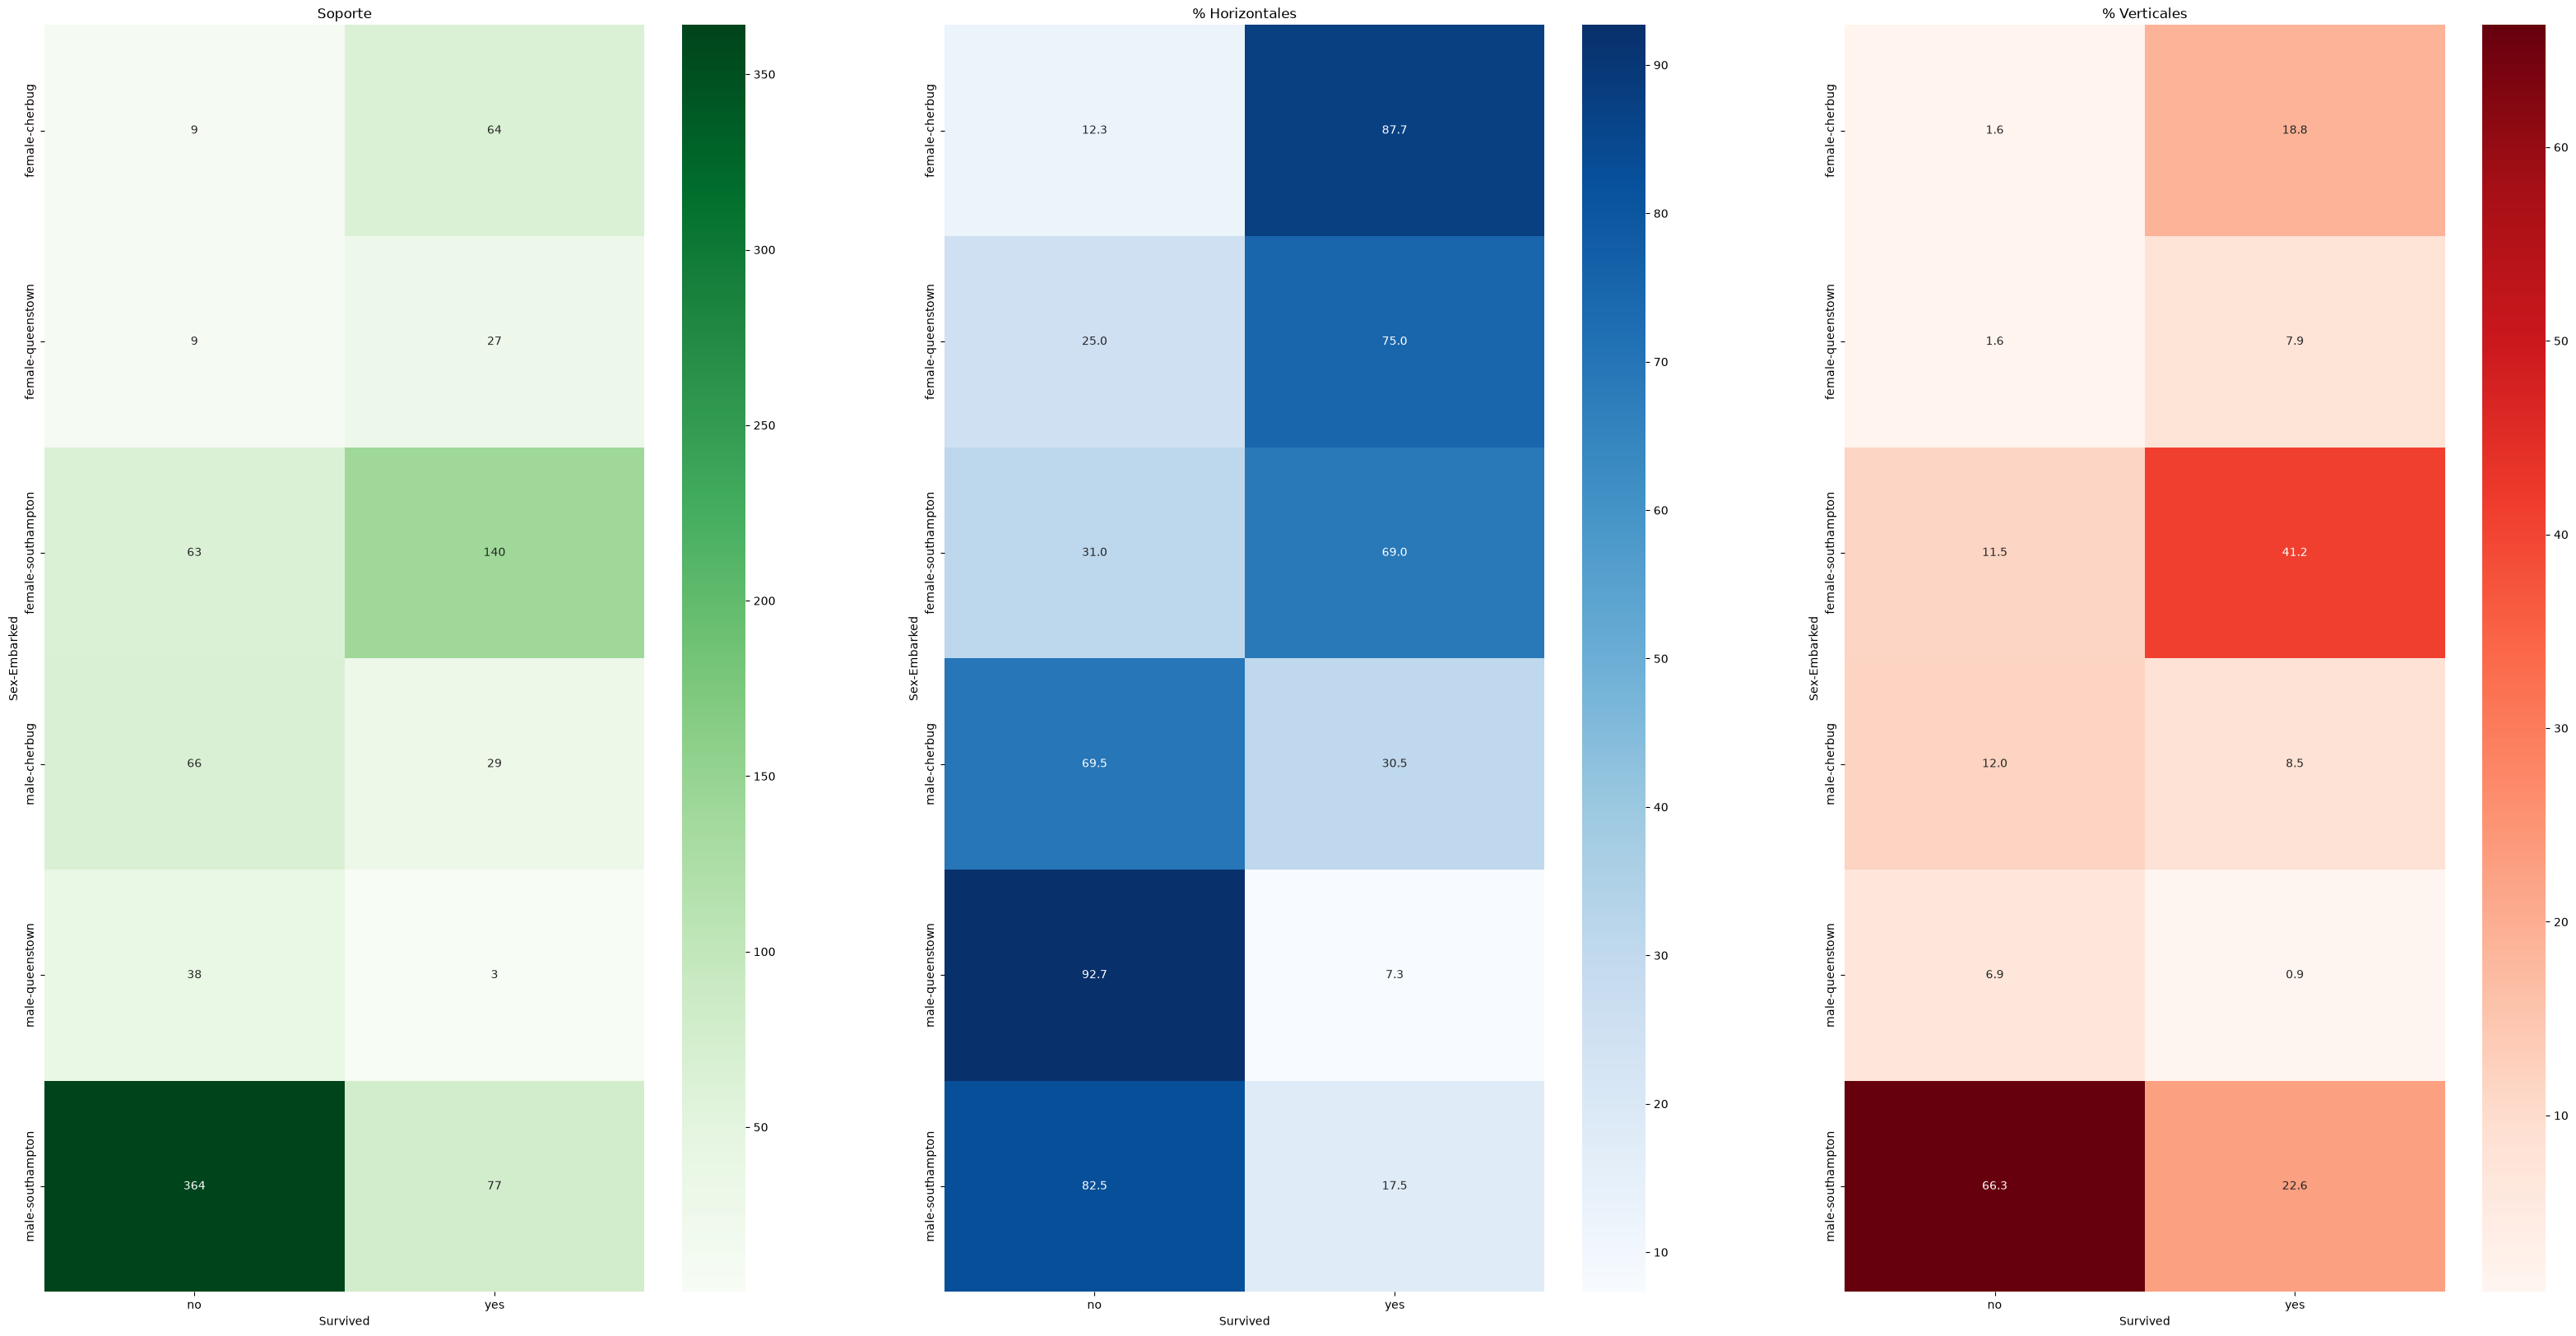

In [64]:
P_ejer2 = reporte_discreto_multiple(X, ["Sex", "Embarked"], "Survived")